# 07 · Análisis del monitoreo, ética y resultado de negocio

Lee lo que la simulación dejó en `PSET2.MLOPS` (monitoreo, alertas, evaluación y reentrenamientos) y responde: ¿qué detectó el monitoreo y con qué falsas alarmas?, ¿qué tipo de deriva fue cada una?, ¿el modelo trata distinto a algún subgrupo?, y ¿valió la pena actuar según la predicción?

In [1]:
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import src.pipeline as P
from src import mlops, estilo
from monitoreo import alertas as A
estilo.aplicar()
pd.set_option("display.width", 200, "display.max_colwidth", 80)

mon = mlops.leer("select * from MONITOREO")
mon = mon.sort_values("calculado_en").drop_duplicates(["lote_id", "etapa", "metrica", "feature"], keep="last")
alertas = mlops.leer("select * from ALERTAS order by lote_id, creada_en")
ev = mlops.leer("select * from EVALUACION")
reent = mlops.leer("select * from REENTRENAMIENTOS")
lotes = mlops.leer("select lote_id, min(fecha) as fecha, max(deriva_inducida) as deriva from LOTES group by 1 order by 1")
ev = ev.merge(mlops.leer("select lote_id, hour_date, hour_of_day, staff_present, iso_day_of_week from LOTES"),
              on=["lote_id", "hour_date", "hour_of_day"])
INDUCIDA = lotes.loc[lotes["deriva"].notna(), "lote_id"].tolist()
REENTRENO = int(reent["lote_disparo"].iloc[0])         # el nuevo champion predice desde el lote siguiente
print("Lotes con deriva inducida:", INDUCIDA, "· reentrenamiento aprobado tras el lote", REENTRENO)

def valor(metrica, etapa=None, feature=None):
    m = mon[mon["metrica"] == metrica]
    if etapa: m = m[m["etapa"] == etapa]
    if feature: m = m[m["feature"] == feature]
    return m.set_index("lote_id")["valor"].sort_index()

Lotes con deriva inducida: [18, 19, 25] · reentrenamiento aprobado tras el lote 21


## 1. Métricas de sistema

      volumen_solicitudes  latencia_p50_ms  latencia_p95_ms  tasa_4xx  tasa_5xx
mean                10.68             7.12            24.85       0.0       0.0
max                 11.00            11.92            37.72       0.0       0.0


PosixPath('/Users/gerart/Documents/proyecto-final/proyecto_final/docs/figuras/monitoreo_latencia.png')

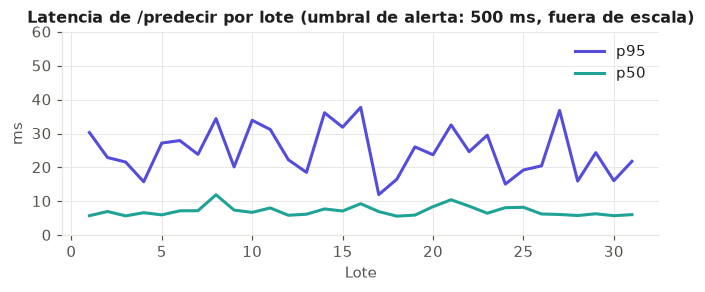

In [2]:
sistema = pd.DataFrame({m: valor(m, "entradas") for m in ["volumen_solicitudes", "latencia_p50_ms", "latencia_p95_ms", "tasa_4xx", "tasa_5xx"]})
print(sistema.describe().loc[["mean", "max"]].round(2))
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.plot(sistema.index, sistema["latencia_p95_ms"], label="p95", color=estilo.INDIGO)
ax.plot(sistema.index, sistema["latencia_p50_ms"], label="p50", color=estilo.TEAL)
ax.axhline(A.LATENCIA_P95_MS, color=estilo.GRIS, ls="--", lw=1)
ax.set(xlabel="Lote", ylabel="ms", title="Latencia de /predecir por lote (umbral de alerta: 500 ms, fuera de escala)", ylim=(0, 60))
ax.legend(loc="upper right"); estilo.guardar(fig, "monitoreo_latencia")

## 2. Métricas de modelo: distribución de predicciones, decisiones y WAPE

In [3]:
modelo = pd.DataFrame({"pred_media": valor("prediccion_media", "entradas"), "psi_predicciones": valor("psi_predicciones", "entradas"),
                       "tasa_reforzar": valor("tasa_reforzar", "entradas"), "wape": valor("wape", "desempeno"),
                       "umbral_wape": mon[mon["metrica"] == "wape"].set_index("lote_id")["umbral"].sort_index(),
                       "version": mon[mon["metrica"] == "wape"].set_index("lote_id")["modelo_version"].sort_index()})
modelo.round(3).T

lote_id,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
pred_media,5.018,5.653,5.195,5.591,5.897,7.438,5.656,6.378,6.719,4.873,...,5.320,5.849,5.751,7.429,6.428,7.480,6.350,5.274,5.683,5.034
psi_predicciones,0.135,0.135,1.643,0.135,0.112,0.029,3.304,1.973,2.097,0.135,...,0.112,0.112,0.135,1.839,0.189,0.029,1.874,0.364,0.028,0.029
tasa_reforzar,0.182,0.091,0.091,0.091,0.091,0.091,0.000,0.500,0.000,0.091,...,0.455,0.091,0.091,0.273,0.182,0.273,0.778,0.545,0.182,0.091
wape,0.578,0.444,0.301,0.308,0.367,0.350,0.481,0.315,0.336,0.349,...,0.335,0.356,0.276,0.392,0.472,0.319,0.327,0.391,0.252,0.552
umbral_wape,0.559,0.559,0.559,0.559,0.559,0.559,0.559,0.559,0.559,0.559,...,0.526,0.526,0.526,0.526,0.526,0.526,0.526,0.526,0.526,0.526
version,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000


PosixPath('/Users/gerart/Documents/proyecto-final/proyecto_final/docs/figuras/monitoreo_wape.png')

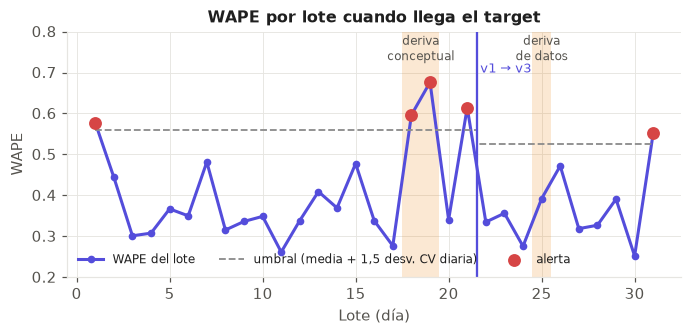

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 2.9))
for l in INDUCIDA:
    ax.axvspan(l - .5, l + .5, color=estilo.AMBAR, alpha=.18, lw=0)
ax.plot(modelo.index, modelo["wape"], marker="o", ms=4, color=estilo.INDIGO, label="WAPE del lote")
ax.step(modelo.index, modelo["umbral_wape"], where="mid", color=estilo.GRIS, ls="--", lw=1.2, label="umbral (media + 1,5 desv. CV diaria)")
al = modelo[modelo["wape"] > modelo["umbral_wape"]]
ax.scatter(al.index, al["wape"], s=55, color="#d64545", zorder=3, label="alerta")
ax.axvline(REENTRENO + .5, color=estilo.INDIGO, lw=1.5)
ax.text(REENTRENO + .7, .70, "v1 → v3", color=estilo.INDIGO, fontsize=8.5)
ax.text(18.5, .73, "deriva\nconceptual", ha="center", fontsize=8, color=estilo.TINTA_2)
ax.text(25, .73, "deriva\nde datos", ha="center", fontsize=8, color=estilo.TINTA_2)
ax.set(xlabel="Lote (día)", ylabel="WAPE", ylim=(.2, .8), title="WAPE por lote cuando llega el target")
ax.legend(loc="lower left", fontsize=8, ncol=3); estilo.guardar(fig, "monitoreo_wape")

## 3. Datos y deriva de datos

lote_id,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
feature,,,,,,,,,,,,,,,,,,,,,
sales_avg_4w_same_hour,0.13,0.90,0.26,0.01,0.24,0.06,0.08,0.88,0.93,0.79,...,0.06,0.03,0.06,1.59,0.06,0.47,0.03,0.52,0.03,0.43
sales_lag_14d,0.02,0.36,0.02,0.14,0.43,0.06,0.08,0.05,0.40,0.58,...,0.37,0.12,0.41,1.24,0.00,0.64,0.52,0.65,0.64,0.50
sales_lag_21d,0.67,0.35,0.08,0.21,0.71,0.04,0.58,0.06,0.42,0.01,...,0.63,0.07,0.38,1.12,0.50,0.11,0.05,0.35,0.11,0.38
sales_lag_28d,0.04,0.72,0.52,0.76,0.05,0.03,0.18,0.64,0.64,0.16,...,0.10,0.30,0.59,2.00,0.74,0.11,0.66,0.77,0.08,0.35
sales_lag_7d,0.07,0.30,0.59,1.16,0.74,0.11,0.61,0.60,0.07,0.36,...,0.42,0.63,0.57,1.37,0.16,0.59,1.35,1.23,0.54,0.56
staff_present,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


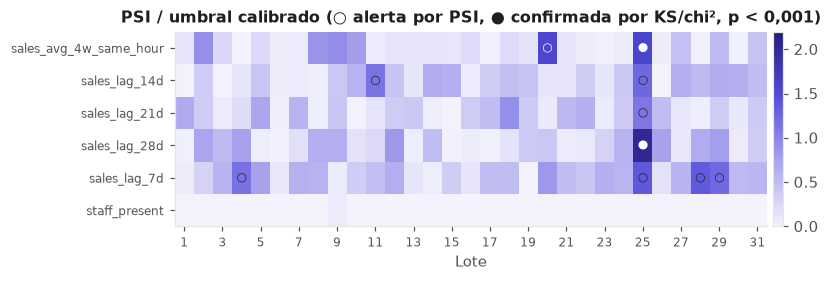

In [5]:
psi = mon[(mon["metrica"] == "psi")].pivot_table(index="feature", columns="lote_id", values="valor")
umb = mon[(mon["metrica"] == "psi")].pivot_table(index="feature", columns="lote_id", values="umbral")
pval = mon[mon["metrica"].str.startswith("p_valor")].pivot_table(index="feature", columns="lote_id", values="valor")
razon = psi / umb
fig, ax = plt.subplots(figsize=(7.2, 2.3))
im = ax.imshow(razon.to_numpy(), aspect="auto", cmap=estilo.SECUENCIAL, vmin=0, vmax=2.2)
ax.set_yticks(range(len(razon)), razon.index, fontsize=8); ax.set_xticks(range(0, 31, 2), razon.columns[::2], fontsize=8)
for (i, j), r in np.ndenumerate(razon.to_numpy()):
    if r > 1:
        confirmada = pval.iloc[i, j] < 0.001
        ax.text(j, i, "●" if confirmada else "○", ha="center", va="center", color="white" if r > 1.4 else estilo.TINTA, fontsize=8)
ax.grid(False); ax.set_xlabel("Lote")
ax.set_title("PSI / umbral calibrado (○ alerta por PSI, ● confirmada por KS/chi², p < 0,001)")
fig.colorbar(im, ax=ax, fraction=.025, pad=.01); estilo.guardar(fig, "monitoreo_psi")
razon.round(2)

In [6]:
calidad = mon[(mon["etapa"] == "entradas") & mon["metrica"].isin(["faltantes", "fuera_rango", "categorias_no_vistas"]) & mon["alerta"]]
calidad[["lote_id", "metrica", "feature", "valor", "umbral"]]

,lote_id,metrica,feature,valor,umbral
1217,25,fuera_rango,ventas_dia_lag_7d,10.0,0.0
1258,26,fuera_rango,ventas_dia_lag_7d,11.0,0.0
1299,27,fuera_rango,ventas_dia_lag_7d,11.0,0.0


**Valores fuera de rango que no son error:** en los lotes 26 y 27, `ventas_dia_lag_7d` vale 105 y 109, sobre el máximo del entrenamiento (98). Es venta real del 13 y 14-11 (la semana más alta de la serie): deriva de datos genuina, sin impacto en el desempeño de esos lotes.

## 4. Alertas: verdaderas y falsas

In [7]:
alertas["lote_alterado"] = alertas["lote_id"].isin(INDUCIDA)
REAL = [26, 27]   # ventas_dia_lag_7d fuera de rango por venta récord real del 13 y 14-11
alertas["tipo"] = np.select([alertas["metrica"].isin(["costo_regla", "wape_seguido"]), alertas["lote_alterado"],
                             alertas["lote_id"].isin(REAL) & (alertas["metrica"] == "fuera_rango")],
                            ["negocio / disparo", "verdadera (lote alterado)", "verdadera (deriva real)"], "falsa alarma (lote sin alterar)")
display(alertas.groupby(["tipo", "metrica", "severidad"]).agg(lotes=("lote_id", lambda s: sorted(set(s))), n=("lote_id", "size")))
falsas = alertas[alertas["tipo"].str.startswith("falsa")]
print(f"Lotes alterados con alerta: {sorted(set(alertas.loc[alertas.lote_alterado, 'lote_id']))} de {INDUCIDA}")
print(f"Falsas alarmas: {len(falsas)} en {falsas['lote_id'].nunique()} lotes sin alterar; Alta: {(falsas['severidad'] == 'Alta').sum()}")

lotes  n
tipo                            metrica      severidad                        
falsa alarma (lote sin alterar) psi          Media      [4, 11, 20, 28, 29]  5
                                wape         Media              [1, 21, 31]  3
negocio / disparo               costo_regla  Alta                  [14, 21]  2
                                wape_seguido Alta                      [21]  1
verdadera (deriva real)         fuera_rango  Media                 [26, 27]  2
verdadera (lote alterado)       fuera_rango  Media                     [25]  1
                                psi          Alta                      [25]  2
                                             Media                     [25]  3
                                wape         Media                 [18, 19]  2

Lotes alterados con alerta: [18, 19, 25] de [18, 19, 25]
Falsas alarmas: 8 en 8 lotes sin alterar; Alta: 0


In [8]:
# ¿Cómo ajustar los umbrales? Razón PSI/umbral de las falsas alarmas frente a las del lote 25.
r_falsas = [razon.loc[f, l] for l, f in falsas.loc[falsas.metrica == "psi", ["lote_id", "feature"]].to_numpy()]
r_25 = razon[25].dropna()
print(f"PSI/umbral de las falsas alarmas: máx {max(r_falsas):.2f} · lote 25: {r_25.round(2).to_dict()}")
for k in [1.0, 1.4, 1.6]:
    falsas_k = sum(r > k for r in r_falsas); det_k = int((r_25 > k).sum())
    print(f"  umbral × {k}: {falsas_k} falsas alarmas de PSI, lote 25 detectado en {det_k} de 5 features")
w = modelo["wape"]
for nombre, u in [("1,5 desv. (actual)", modelo["umbral_wape"]), ("2 desv.", modelo["umbral_wape"] + 0.5 * 0.111)]:
    sobre = w[w > u].index.tolist()
    print(f"WAPE con {nombre}: alertas en {sobre}; alterados detectados {[l for l in sobre if l in INDUCIDA]}")

PSI/umbral de las falsas alarmas: máx 1.56 · lote 25: {'sales_avg_4w_same_hour': 1.59, 'sales_lag_14d': 1.24, 'sales_lag_21d': 1.12, 'sales_lag_28d': 2.0, 'sales_lag_7d': 1.37, 'staff_present': 0.0}
  umbral × 1.0: 5 falsas alarmas de PSI, lote 25 detectado en 5 de 5 features
  umbral × 1.4: 1 falsas alarmas de PSI, lote 25 detectado en 2 de 5 features
  umbral × 1.6: 0 falsas alarmas de PSI, lote 25 detectado en 1 de 5 features
WAPE con 1,5 desv. (actual): alertas en [1, 18, 19, 21, 31]; alterados detectados [18, 19]
WAPE con 2 desv.: alertas en [19]; alterados detectados [19]


**Decisión sobre las falsas alarmas.** Las 8 falsas alarmas son de severidad Media y ninguna disparó una acción. Las 5 de PSI las marcó el PSI y la prueba estadística no las confirmó: con ~11 filas por lote, el PSI de un día normal ya es alto. Subir el umbral no las separa bien del lote alterado (la peor falsa alarma, 1,56 veces el umbral, está a la altura del lote 25), así que el ajuste no es mover el umbral sino el que ya se aplica: el PSI solo avisa y la confirmación de KS/chi² (p < 0,001) decide la severidad Alta, que es la que excluye el lote del reentrenamiento. Con más filas por lote (lotes semanales en operación real) el PSI deja de ser tan ruidoso y el umbral podría bajar. Las 3 de WAPE (lotes 1, 21 y 31) tampoco se corrigen subiendo el umbral: con 2 desviaciones se pierde el lote 18. Por eso la acción (reentrenar) exige 2 lotes seguidos y una alerta aislada solo pide diagnóstico.

## 5. Diagnóstico por tipo de deriva

In [9]:
diag = pd.DataFrame({"entradas_cambian": [bool(((alertas.lote_id == l) & alertas.metrica.isin(["psi", "fuera_rango"]) & (alertas.severidad == "Alta")).any()
                                              or ((calidad.lote_id == l) & (calidad.metrica == "fuera_rango")).any()) for l in modelo.index],
                     "desempeno_cae": (modelo["wape"] > modelo["umbral_wape"]).to_numpy()}, index=modelo.index)
# Deriva conceptual = el desempeño cae en 2 lotes SEGUIDOS sin que cambien las entradas; una caída aislada es ruido.
cae = diag["desempeno_cae"]
seguida = cae & (cae.shift(1, fill_value=False) | cae.shift(-1, fill_value=False))
diag["diagnostico"] = np.select([diag.entradas_cambian & ~cae, diag.entradas_cambian & cae, ~diag.entradas_cambian & seguida,
                                 ~diag.entradas_cambian & cae], ["deriva de datos sin impacto", "deriva de datos con impacto",
                                 "deriva conceptual", "caída aislada (ruido)"], "estable")
diag = diag.join(lotes.set_index("lote_id")[["fecha", "deriva"]])
diag[diag["diagnostico"] != "estable"]

,entradas_cambian,desempeno_cae,diagnostico,fecha,deriva
lote_id,,,,,
1,False,True,caída aislada (ruido),2026-10-26,NaN
18,False,True,deriva conceptual,2026-11-12,"conceptual: ventas reales x2, entradas sin cambio"
19,False,True,deriva conceptual,2026-11-13,"conceptual: ventas reales x2, entradas sin cambio"
21,False,True,caída aislada (ruido),2026-11-15,NaN
25,True,False,deriva de datos sin impacto,2026-11-19,datos: rezagos de la sucursal 2 (join sin filtro de branch_id)
26,True,False,deriva de datos sin impacto,2026-11-20,NaN
27,True,False,deriva de datos sin impacto,2026-11-21,NaN
31,False,True,caída aislada (ruido),2026-11-25,NaN


| Entradas | Desempeño | Diagnóstico | Acción en este proyecto | Lotes |
|---|---|---|---|---|
| Cambian | Se mantiene | Deriva de datos sin impacto | Revisar la fuente (equipo de datos); **no reentrenar**; si el valor es un error, excluir el lote de futuros entrenamientos (automático con alerta Alta) | 25 (inducida), 26-27 (venta récord real) |
| Cambian | Cae | Deriva de datos con impacto | Corregir la fuente primero; si el cambio es real y persiste, reentrenar con datos que lo incluyan; si cuesta más que la regla, activar el respaldo | — |
| Estables | Cae | Deriva conceptual | Una alerta aislada: diagnosticar. 2 lotes seguidos: reentrenamiento con aprobación humana | 18-19 (inducida) → reentrenamiento; 1, 21, 31 (aisladas, ruido) |

El lote 25 confirma por qué este modelo es poco sensible a la deriva de los rezagos: Ridge les da coeficientes pequeños y de signos opuestos (el total del día de hace una semana pesa en negativo), así que rezagos de la sucursal 2 (un tercio de la venta) apenas mueven la predicción.

## 6. Ética operativa: desempeño por subgrupo

In [10]:
ev["reforzar_modelo"] = ev["decision"] == "reforzar"
base = ev[~ev["lote_id"].isin(INDUCIDA)].copy()      # los lotes alterados no describen a nadie real
base["subgrupo_personal"] = np.where(base["staff_present"] == 1, "1 vendedor", "2 vendedores")
base["subgrupo_dia"] = np.where(base["iso_day_of_week"] >= 6, "sábado y domingo", "lunes a viernes")
def resumen(g):
    real = g["reforzar_real"].astype(bool); pred = g["reforzar_modelo"]
    return pd.Series({"horas": len(g), "wape": P.wape(g["ventas_reales"], g["ventas_previstas"]),
                      "sesgo_medio": (g["ventas_previstas"] - g["ventas_reales"]).mean(),
                      "tasa_refuerzo_modelo": pred.mean(), "tasa_sobrecarga_real": real.mean(),
                      "sobrecargas_no_cubiertas": int((real & ~pred).sum()),
                      "recall_sobrecarga": (real & pred).sum() / real.sum() if real.sum() else np.nan,
                      "refuerzos_innecesarios": int((~real & pred).sum())})
sub = pd.concat({"personal": base.groupby("subgrupo_personal").apply(resumen), "día": base.groupby("subgrupo_dia").apply(resumen)})
sub.round(3)

horas   wape  sesgo_medio  tasa_refuerzo_modelo  tasa_sobrecarga_real  sobrecargas_no_cubiertas  recall_sobrecarga  refuerzos_innecesarios
personal 1 vendedor        165.0  0.424       -0.400                 0.327                 0.309                      24.0              0.529                    27.0
         2 vendedores      133.0  0.313       -0.859                 0.000                 0.023                       3.0              0.000                     0.0
día      lunes a viernes   218.0  0.359       -0.506                 0.165                 0.128                      10.0              0.643                    18.0
         sábado y domingo   80.0  0.389       -0.873                 0.225                 0.325                      17.0              0.346                     9.0

**Lectura.** Casi todas las sobrecargas ocurren en horas con **1 vendedor** (lunes, domingo y las de almuerzo): con 2 vendedores la carga casi nunca llega a 8 ventas por persona (2 % de las horas), así que esa diferencia es de diseño del turno, no del modelo. La diferencia que sí es del modelo está entre **días**: el fin de semana subpredice más (sesgo −0,87 ventas por hora) y detecta solo 35 % de las sobrecargas, frente a 64 % entre semana; 17 de las 27 sobrecargas no cubiertas caen en sábado o domingo. Para el negocio es tolerable (cada una cuesta ~$7), pero para las personas no: quien trabaja sola el domingo absorbe en esfuerzo, y los clientes en espera, justo el error más frecuente. Por eso el ajuste propuesto es un umbral de decisión propio para el fin de semana (elegido con predicciones fuera de pliegue, como el general) y un criterio de retirada que vigile esta brecha (sección 8).

## 7. Resultado de negocio lote por lote

In [11]:
neg = pd.DataFrame({k: valor(k, "desempeno") for k in ["costo_modelo", "costo_regla", "costo_no_hacer_nada"]})
neg["version"] = modelo["version"]
neg = neg.join(lotes.set_index("lote_id")[["fecha"]])
neg["ahorro_vs_regla"] = neg["costo_regla"] - neg["costo_modelo"]
tramos = {"v1 (lotes 1-21)": neg.loc[:REENTRENO], f"v3 (lotes {REENTRENO+1}-31)": neg.loc[REENTRENO+1:],
          "total": neg, "total sin lotes alterados": neg.drop(INDUCIDA)}
resultado = pd.DataFrame({k: v[["costo_modelo", "costo_regla", "costo_no_hacer_nada"]].sum() for k, v in tramos.items()}).T
resultado["ahorro_vs_regla"] = resultado["costo_regla"] - resultado["costo_modelo"]
resultado["ahorro_vs_nada"] = resultado["costo_no_hacer_nada"] - resultado["costo_modelo"]
display(resultado.round(2))
neg.round(2)

,costo_modelo,costo_regla,costo_no_hacer_nada,ahorro_vs_regla,ahorro_vs_nada
v1 (lotes 1-21),271.72,255.82,345.12,-15.90,73.40
v3 (lotes 22-31),78.35,116.56,143.80,38.21,65.45
total,350.07,372.38,488.92,22.31,138.85
total sin lotes alterados,265.68,286.10,388.26,20.42,122.58


,costo_modelo,costo_regla,costo_no_hacer_nada,version,fecha,ahorro_vs_regla
lote_id,,,,,,
1,5.30,5.30,0.00,1,2026-10-26,0.00
2,0.00,0.00,7.19,1,2026-10-27,0.00
3,0.00,0.00,7.19,1,2026-10-28,0.00
4,7.19,7.19,14.38,1,2026-10-29,0.00
5,7.19,7.19,14.38,1,2026-10-30,0.00
6,9.84,9.84,7.19,1,2026-10-31,0.00
7,28.76,21.57,28.76,1,2026-11-01,-7.19
8,7.95,7.19,14.38,1,2026-11-02,-0.76
9,0.00,0.00,0.00,1,2026-11-03,0.00


PosixPath('/Users/gerart/Documents/proyecto-final/proyecto_final/docs/figuras/negocio_lotes.png')

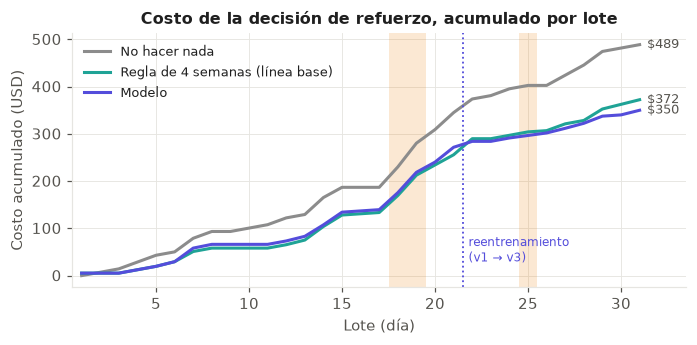

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
acum = neg[["costo_modelo", "costo_regla", "costo_no_hacer_nada"]].cumsum()
for col, color, nombre in [("costo_no_hacer_nada", estilo.GRIS, "No hacer nada"), ("costo_regla", estilo.TEAL, "Regla de 4 semanas (línea base)"),
                           ("costo_modelo", estilo.INDIGO, "Modelo")]:
    ax.plot(acum.index, acum[col], color=color, label=nombre)
    ax.text(31.4, acum[col].iloc[-1], f"${acum[col].iloc[-1]:.0f}", va="center", fontsize=8.5, color=estilo.TINTA_2)
for l in INDUCIDA:
    ax.axvspan(l - .5, l + .5, color=estilo.AMBAR, alpha=.18, lw=0)
ax.axvline(REENTRENO + .5, color=estilo.INDIGO, lw=1.2, ls=":")
ax.text(REENTRENO + .8, 30, "reentrenamiento\n(v1 → v3)", fontsize=8, color=estilo.INDIGO)
ax.set(xlabel="Lote (día)", ylabel="Costo acumulado (USD)", xlim=(0.5, 33.5), title="Costo de la decisión de refuerzo, acumulado por lote")
ax.legend(loc="upper left", fontsize=8.5); estilo.guardar(fig, "negocio_lotes")

## 8. Criterios de retirada, evaluados sobre la simulación

In [13]:
ventanas = neg[["costo_modelo", "costo_regla"]].rolling(14).sum().dropna()
peor_que_regla = ventanas[ventanas.costo_modelo > ventanas.costo_regla]
print("Ventanas de 14 lotes donde el modelo costó más que la regla (criterio 1):",
      [f"hasta lote {i}" for i in peor_que_regla.index[[0, -1]]] if len(peor_que_regla) else "ninguna")
print("  -> la última termina en el lote", peor_que_regla.index.max(), "; después del reentrenamiento el modelo vuelve a ganarle a la regla.")
rec = base.groupby("subgrupo_dia").apply(lambda g: ((g.reforzar_real.astype(bool) & g.reforzar_modelo).sum() / g.reforzar_real.astype(bool).sum()))
print("Recall de sobrecargas por tipo de día (criterio 3: brecha > 0,25 en 2 semanas):", rec.round(2).to_dict(),
      f"-> brecha {rec.max() - rec.min():.2f}: el criterio de ajuste se cumple")
print("Tasa de 5xx máxima (criterio 2):", sistema["tasa_5xx"].max())

Ventanas de 14 lotes donde el modelo costó más que la regla (criterio 1): ['hasta lote 14', 'hasta lote 21']
  -> la última termina en el lote 21 ; después del reentrenamiento el modelo vuelve a ganarle a la regla.
Recall de sobrecargas por tipo de día (criterio 3: brecha > 0,25 en 2 semanas): {'lunes a viernes': 0.64, 'sábado y domingo': 0.35} -> brecha 0.30: el criterio de ajuste se cumple
Tasa de 5xx máxima (criterio 2): 0.0
